In [ ]:
#pip install --upgrade pygad

MELHOR SOLUÇÃO ENCONTRADA
Cromossomo: [1 1 1 1 1]
Valor decimal (x): 31
Fitness f(x)=x²: 961


/usr/local/lib/python3.13/dist-packages/pygad/utils/validation.py:1914: UserWarning: Use the 'save_best_solutions' parameter with caution as it may cause memory overflow when either the number of generations or number of genes is large.
  warnings.warn("Use the 'save_best_solutions' parameter with caution as it may cause memory overflow when either the number of generations or number of genes is large.")


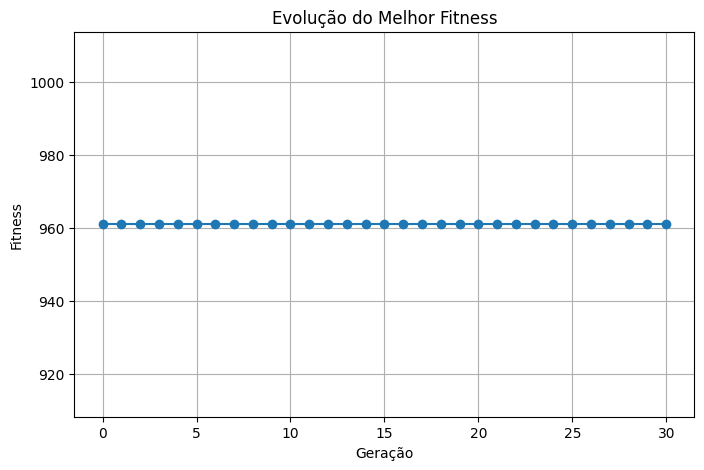

In [ ]:
# ==========================================================
# ALGORITMOS GENÉTICOS COM PYGAD
# Exemplo: Maximizar f(x) = x²
# ==========================================================

# Instala a biblioteca (executar apenas uma vez no Colab)
!pip install --upgrade pygad

# Importação das bibliotecas
import pygad
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# REPRESENTAÇÃO DO PROBLEMA
# ==========================================================
#
# Objetivo:
# Encontrar o valor de x que maximize a função:
#
#           f(x) = x²
#
# O valor de x será representado usando 5 bits.
#
# Exemplos:
#
# [0,0,0,0,0] -> 0
# [0,0,0,0,1] -> 1
# [1,0,1,0,1] -> 21
# [1,1,1,1,1] -> 31
#
# Portanto:
# x pode variar entre 0 e 31.
#
# Cada indivíduo da população é um cromossomo.
# Cada posição do cromossomo é um gene.
#
# Exemplo:
#
# Cromossomo = [1,0,1,0,1]
#
# Gene 1 = 1
# Gene 2 = 0
# Gene 3 = 1
# Gene 4 = 0
# Gene 5 = 1
#
# ==========================================================


# ==========================================================
# FUNÇÃO AUXILIAR
# ==========================================================
#
# Converte um cromossomo binário para decimal.
#
# Exemplo:
# [1,0,1,0,1]
#
# vira:
# "10101"
#
# e depois:
# 21
#
# ==========================================================

def binario_para_decimal(solution):
    binario = "".join(str(int(gene)) for gene in solution)
    return int(binario, 2)


# ==========================================================
# FUNÇÃO FITNESS
# ==========================================================
#
# A função fitness indica quão boa é uma solução.
#
# Quanto maior o fitness:
# melhor o indivíduo.
#
# Neste exemplo:
#
# fitness = x²
#
# Assim:
#
# x = 5  -> fitness = 25
# x = 20 -> fitness = 400
# x = 31 -> fitness = 961
#
# O AG tentará encontrar automaticamente
# o indivíduo com maior fitness.
#
# ==========================================================

def fitness_func(ga_instance, solution, solution_idx):

    # converte cromossomo para decimal
    x = binario_para_decimal(solution)

    # calcula aptidão
    fitness = x ** 2

    return fitness


# ==========================================================
# CONFIGURAÇÃO DO ALGORITMO GENÉTICO
# ==========================================================

ga_instance = pygad.GA(

    # número de gerações
    num_generations=30,
    gene_type=int,

    # quantidade de indivíduos por população
    sol_per_pop=20,

    # quantidade de pais selecionados
    num_parents_mating=6,

    # número de genes por indivíduo
    num_genes=5,

    # cada gene pode assumir apenas 0 ou 1
    gene_space=[0, 1],

    # função de avaliação
    fitness_func=fitness_func,

    # seleção por roleta
    parent_selection_type="rws",

    # crossover de um ponto
    crossover_type="single_point",

    # mutação aleatória
    mutation_type="random",

    # percentual dos genes que sofrerão mutação
    mutation_percent_genes=20,

    # salva o melhor indivíduo de cada geração
    save_best_solutions=True

)

# ==========================================================
# EXECUÇÃO DO AG
# ==========================================================
#
# Processo:
#
# 1) cria população inicial aleatória
# 2) avalia fitness
# 3) seleciona pais
# 4) realiza crossover
# 5) realiza mutação
# 6) gera nova população
# 7) repete até atingir o número de gerações
#
# ==========================================================

ga_instance.run()


# ==========================================================
# MELHOR SOLUÇÃO ENCONTRADA
# ==========================================================

solution, solution_fitness, solution_idx = ga_instance.best_solution()

x_final = binario_para_decimal(solution)

print("=" * 50)
print("MELHOR SOLUÇÃO ENCONTRADA")
print("=" * 50)

print("Cromossomo:", solution)

print("Valor decimal (x):", x_final)

print("Fitness f(x)=x²:", solution_fitness)


# ==========================================================
# EVOLUÇÃO DO FITNESS
# ==========================================================
#
# Este gráfico mostra como a melhor solução
# melhora ao longo das gerações.
#
# Se o gráfico cresce:
# o algoritmo está encontrando soluções melhores.
#
# ==========================================================

plt.figure(figsize=(8,5))

plt.plot(
    ga_instance.best_solutions_fitness,
    marker="o"
)

plt.title("Evolução do Melhor Fitness")

plt.xlabel("Geração")

plt.ylabel("Fitness")

plt.grid(True)

plt.show()